# Giai đoạn 2 — Feature Engineering

Notebook này tập trung vào **tạo và kiểm tra feature**:

1. Tải dữ liệu train (có nhãn) để kiểm tra feature.
2. Gọi `add_features()` từ `src/features.py` — logic tái sử dụng được.
3. Kiểm tra shape, dtypes, missing values sau khi tạo feature.
4. Thống kê mô tả và phân phối các feature mới.
5. So sánh phân phối feature giữa giao dịch fraud và non-fraud.
6. Kiểm tra tương quan giữa các feature mới.

> **Không có** model fitting, cross-validation hay tạo submission trong notebook này.
> Các bước đó thuộc về `03_modeling.ipynb`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Thêm thư mục gốc dự án vào sys.path để import src/
PROJECT_ROOT = Path("../").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features import (
    RAW_NUMERIC_COLUMNS,
    RAW_CATEGORICAL_COLUMNS,
    RAW_BOOLEAN_COLUMNS,
    ENGINEERED_NUMERIC_COLUMNS,
    ADVANCED_NUMERIC_COLUMNS,
    INTERACTION_COLUMNS,
    FEATURE_GROUPS,
    FEATURE_SETS,
    add_features,
)

DATA_DIR = PROJECT_ROOT / "data"

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

## 1. Tải dữ liệu

In [2]:
train_raw = pd.read_csv(DATA_DIR / "train.csv")

target = train_raw["is_fraud"].astype(np.int8)
X_raw = train_raw.drop(columns="is_fraud")

print("Shape train (trước FE):", X_raw.shape)
print(f"Tỷ lệ fraud: {target.mean():.4%}")

Shape train (trước FE): (699960, 25)
Tỷ lệ fraud: 1.6700%


## 2. Tạo feature

Logic tạo feature nằm trong `src/features.py::add_features()`.
Hàm này sẽ được tái sử dụng trong notebook modeling.

In [3]:
X = add_features(X_raw)

print("Shape sau FE:", X.shape)
print(f"Số feature mới thêm: {X.shape[1] - X_raw.shape[1]}")

Shape sau FE: (699960, 44)
Số feature mới thêm: 19


## 3. Kiểm tra schema sau Feature Engineering

In [4]:
print("=== Dtypes ===")
print(X.dtypes.to_string())
print()
print("=== Missing values ===")
missing = X.isna().sum()
print(missing[missing > 0] if missing.any() else "Không có missing values.")

=== Dtypes ===
id                                   int64
amount_usd                         float64
hours_since_last_txn               float64
txn_count_last_24h                   int64
distance_from_home_km              float64
card_age_months                      int64
customer_age                         int64
account_balance_usd                float64
cvv_retry_count                      int64
velocity_score                     float64
time_of_day_hour                     int64
day_of_week                          int64
merchant_risk_score                float64
prior_disputes                       int64
merchant_category                 category
card_type                         category
auth_method                       category
channel                           category
device_type                       category
is_foreign_transaction             float32
is_new_merchant                    float32
used_vpn                           float32
ip_country_mismatch                floa

In [5]:
# Danh sách các feature mới (numeric và interaction)
new_numeric_cols = (
    ENGINEERED_NUMERIC_COLUMNS
    + ADVANCED_NUMERIC_COLUMNS
)

interaction_cols = INTERACTION_COLUMNS

print("Feature số mới:", new_numeric_cols)
print()
print("Feature tương tác (categorical):", interaction_cols)

Feature số mới: ['txn_intensity_per_hour', 'txn_intensity_per_day', 'balance_amount_ratio', 'prior_disputes_per_card_age', 'risk_flag_count', 'network_risk_count', 'vpn_ip_mismatch', 'foreign_ip_mismatch', 'cvv_velocity_risk', 'cvv_merchant_risk', 'cvv_binary_risk', 'no_auth_merchant_risk', 'no_auth_binary_risk', 'new_merchant_risk', 'new_merchant_no_auth', 'amount_velocity_risk', 'amount_merchant_risk', 'distance_foreign']

Feature tương tác (categorical): ['merchant_category__auth_method']


## 4. Thống kê mô tả các feature số mới

In [6]:
X[new_numeric_cols].describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
txn_intensity_per_hour,699960.0,1.7225,4.9794,0.0000,0.2604,0.5744,1.3598,174.1935
txn_intensity_per_day,699960.0,2.4256,1.3039,0.0000,1.5474,2.3159,3.2182,9.9875
balance_amount_ratio,699960.0,95.5609,210.7931,0.0684,24.5002,51.5804,106.7905,23884.2167
prior_disputes_per_card_age,699960.0,0.0032,0.0081,0.0000,0.0000,0.0000,0.0000,0.0938
risk_flag_count,699960.0,0.2327,0.4712,0.0000,0.0000,0.0000,0.0000,5.0000
network_risk_count,699960.0,0.0673,0.2758,0.0000,0.0000,0.0000,0.0000,3.0000
vpn_ip_mismatch,699960.0,0.0008,0.0290,0.0000,0.0000,0.0000,0.0000,1.0000
foreign_ip_mismatch,699960.0,0.0050,0.0708,0.0000,0.0000,0.0000,0.0000,1.0000
cvv_velocity_risk,699960.0,1.6876,6.6683,0.0000,0.0000,0.0000,0.0000,145.8000
cvv_merchant_risk,699960.0,3.1083,11.3489,0.0000,0.0000,0.0000,0.0000,258.0000


## 5. So sánh phân phối feature giữa fraud và non-fraud

Mục tiêu: nhận biết feature nào có khả năng phân biệt tốt giữa hai lớp.

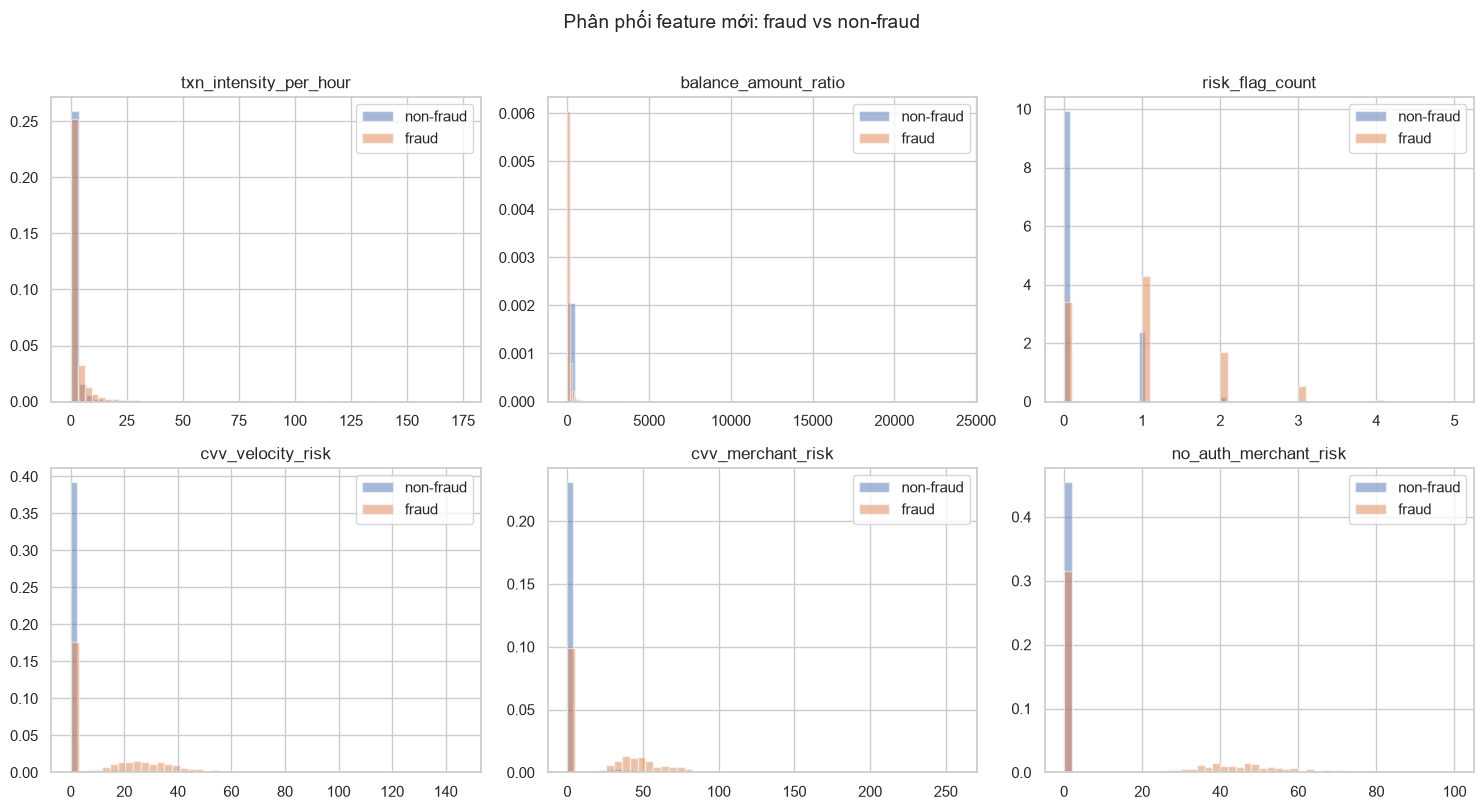

In [7]:
plot_cols = [
    "txn_intensity_per_hour",
    "balance_amount_ratio",
    "risk_flag_count",
    "cvv_velocity_risk",
    "cvv_merchant_risk",
    "no_auth_merchant_risk",
]

X_plot = X[plot_cols].copy()
X_plot["is_fraud"] = target

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, plot_cols):
    for label, grp in X_plot.groupby("is_fraud")[col]:
        # Vẽ histogram bằng matplotlib để tránh seaborn KDE lỗi với dữ liệu lớn
        ax.hist(
            grp,
            bins=50,
            density=True,
            alpha=0.5,
            label="fraud" if label == 1 else "non-fraud",
        )
    ax.set_title(col)
    ax.legend()

plt.suptitle("Phân phối feature mới: fraud vs non-fraud", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 6. Kiểm tra các feature nhị phân

In [8]:
binary_cols = RAW_BOOLEAN_COLUMNS + [
    "vpn_ip_mismatch",
    "foreign_ip_mismatch",
    "new_merchant_no_auth",
]

summary_rows = []
for col in binary_cols:
    fraud_rate_0 = target[X[col] == 0].mean()
    fraud_rate_1 = target[X[col] == 1].mean()
    pct_ones = X[col].mean()
    summary_rows.append({
        "feature": col,
        "% value=1": f"{pct_ones:.2%}",
        "fraud_rate (val=0)": f"{fraud_rate_0:.4%}",
        "fraud_rate (val=1)": f"{fraud_rate_1:.4%}",
    })

pd.DataFrame(summary_rows).set_index("feature")

,% value=1,fraud_rate (val=0),fraud_rate (val=1)
feature,,,
is_foreign_transaction,1.73%,1.4782%,12.5723%
is_new_merchant,15.25%,1.1188%,4.7339%
used_vpn,3.38%,1.4992%,6.5498%
ip_country_mismatch,1.62%,1.4264%,16.4958%
billing_shipping_mismatch,1.29%,1.5216%,12.9887%
is_ai_generated_scam_attempt,0.33%,1.6253%,15.2240%
vpn_ip_mismatch,0.08%,1.6346%,43.7075%
foreign_ip_mismatch,0.50%,1.5472%,25.8850%
new_merchant_no_auth,1.58%,1.4334%,16.4461%


## 7. Kiểm tra các feature tương tác (categorical)

Xem số lượng giá trị unique và top giá trị theo fraud rate.

In [9]:
for col in INTERACTION_COLUMNS:
    n_unique = X[col].nunique()
    top = (
        pd.DataFrame({"feature": X[col], "is_fraud": target})
        .groupby("feature")["is_fraud"]
        .agg(["mean", "count"])
        .rename(columns={"mean": "fraud_rate", "count": "n"})
        .sort_values("fraud_rate", ascending=False)
        .head(5)
    )
    print(f"\n=== {col} | unique={n_unique} ===")
    display(top)


=== merchant_category__auth_method | unique=60 ===


,fraud_rate,n
feature,,
Gift Cards__No Authentication,0.230072,1104
Crypto Exchange__No Authentication,0.223176,466
Gaming__No Authentication,0.190947,2629
Electronics__No Authentication,0.113361,4543
Streaming__No Authentication,0.086847,4744


## 8. Tương quan giữa các feature số mới và target

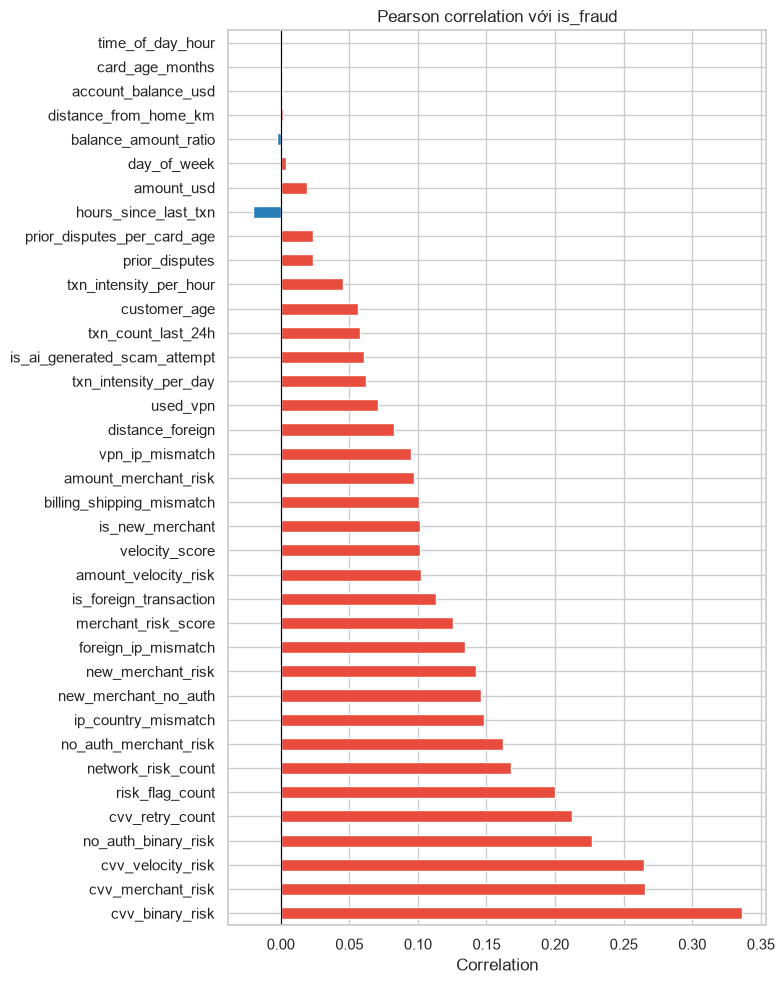

cvv_binary_risk                 0.3361
cvv_merchant_risk               0.2658
cvv_velocity_risk               0.2651
no_auth_binary_risk             0.2271
cvv_retry_count                 0.2123
risk_flag_count                 0.1998
network_risk_count              0.1678
no_auth_merchant_risk           0.1618
ip_country_mismatch             0.1483
new_merchant_no_auth            0.1459
new_merchant_risk               0.1420
foreign_ip_mismatch             0.1346
merchant_risk_score             0.1254
is_foreign_transaction          0.1128
amount_velocity_risk            0.1021
velocity_score                  0.1016
is_new_merchant                 0.1014
billing_shipping_mismatch       0.1011
amount_merchant_risk            0.0969
vpn_ip_mismatch                 0.0951
distance_foreign                0.0828
used_vpn                        0.0712
txn_intensity_per_day           0.0623
is_ai_generated_scam_attempt    0.0607
txn_count_last_24h              0.0580
customer_age             

In [10]:
all_numeric = (
    RAW_NUMERIC_COLUMNS
    + RAW_BOOLEAN_COLUMNS
    + ENGINEERED_NUMERIC_COLUMNS
    + ADVANCED_NUMERIC_COLUMNS
)
existing_numeric = [c for c in all_numeric if c in X.columns]

corr_with_target = (
    X[existing_numeric]
    .assign(is_fraud=target)
    .corr()["is_fraud"]
    .drop("is_fraud")
    .sort_values(key=abs, ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 10))
corr_with_target.plot.barh(ax=ax, color=corr_with_target.map(lambda v: "#e74c3c" if v > 0 else "#2980b9"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Pearson correlation với is_fraud")
ax.set_xlabel("Correlation")
plt.tight_layout()
plt.show()

print(corr_with_target.round(4).to_string())